# Actividad 2 – Regresión logística: predicción del sistema operativo del visitante
**Materia:** Aprendizaje Automático 

## 0. La pregunta
> *¿Se puede predecir qué sistema operativo (Windows, Macintosh o Linux) usa un visitante de un sitio web, a partir de cómo se comportó durante la sesión?*

- **Variable objetivo `y`:** `clase`, discreta con 3 categorías (0=Windows, 1=Macintosh, 2=Linux) → es un problema de **clasificación multiclase**. Que la salida esté codificada con números no lo convierte en un problema de regresión: la tarea la define el significado de `y`, no el tipo de dato con el que se guarda.
- **Entradas `X`:** duración de la visita, páginas vistas, cantidad de acciones y suma del valor de las acciones. Son datos de comportamiento durante la sesión, disponibles en el momento de predecir.
- **Dataset:** `usuarios_win_mac_lin.csv`, provisto por la cátedra, 170 registros.
- **Método:** preparación → exploración → modelado (regresión logística).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn import linear_model
from sklearn.metrics import (classification_report, confusion_matrix,
                              ConfusionMatrixDisplay, accuracy_score)

## 1. Preparación y organización de datos

In [2]:
df = pd.read_csv("usuarios_win_mac_lin.csv")
print(df.shape)
df.head()

(170, 5)


,duracion,paginas,acciones,valor,clase
0,7.0,2,4,8,2
1,21.0,2,6,6,2
2,57.0,2,4,4,2
3,101.0,3,6,12,2
4,109.0,2,6,12,2


### 1.1 Inspeccionar antes de transformar 

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   duracion  170 non-null    float64
 1   paginas   170 non-null    int64  
 2   acciones  170 non-null    int64  
 3   valor     170 non-null    int64  
 4   clase     170 non-null    int64  
dtypes: float64(1), int64(4)
memory usage: 6.8 KB


In [4]:
print("Faltantes por columna:"); print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())
print("\nDistribución de clases:"); print(df["clase"].value_counts())
df.describe().round(2)

Faltantes por columna:
duracion    0
paginas     0
acciones    0
valor       0
clase       0
dtype: int64

Filas duplicadas: 16

Distribución de clases:
clase
0    86
2    44
1    40
Name: count, dtype: int64


,duracion,paginas,acciones,valor,clase
count,170.00,170.00,170.00,170.00,170.00
mean,111.08,2.04,8.72,32.68,0.75
std,202.45,1.50,9.14,44.75,0.84
min,1.00,1.00,1.00,1.00,0.00
25%,11.00,1.00,3.00,8.00,0.00
50%,13.00,2.00,6.00,20.00,0.00
75%,108.00,2.00,10.00,36.00,2.00
max,898.00,9.00,63.00,378.00,2.00


**Observaciones:**
- No hay valores faltantes.
- Hay 16 filas exactamente duplicadas. Antes de eliminarlas reviso a qué corresponden.

In [5]:
duplicados = df[df.duplicated(keep=False)].sort_values(list(df.columns))
duplicados.head(10)

,duracion,paginas,acciones,valor,clase
97,11.0,1,2,4,2
125,11.0,1,2,4,2
143,11.0,1,2,6,0
149,11.0,1,2,6,0
119,11.0,1,3,3,2
124,11.0,1,3,3,2
127,11.0,1,3,3,2
114,11.0,1,3,6,2
120,11.0,1,3,6,2
147,11.0,1,5,15,0


Las filas duplicadas tienen valores bajos en `paginas` y `acciones` (por ejemplo, duración=11 s, 1 página, 2 acciones, valor=4). Con variables de conteo tan chicas, es esperable que dos **sesiones distintas** de usuarios distintos coincidan por azar en los mismos valores redondeados: no hay ningún identificador de usuario en el dataset que indique que se trate de la misma persona registrada dos veces. Siguiendo el criterio de lo que vimos en clase ("dos compras iguales pueden ser dos operaciones válidas"), **no elimino estas filas**: no tengo evidencia de que sean un error de carga y sí es plausible que sean sesiones distintas con comportamiento idéntico.
- Reglas de calidad: duración, páginas y acciones deberían ser positivas. Lo verifico.
- Las clases están algo desbalanceadas: 86 Windows, 44 Linux y 40 Macintosh (sobre 170). No es un desbalance tan extremo, pero conviene tenerlo presente al elegir la métrica (no alcanza con mirar solo accuracy).
- `clase` es la salida discreta: no la trato como una cantidad ni la escalo.

In [6]:
print("duracion <= 0:", (df["duracion"] <= 0).sum())
print("paginas <= 0:", (df["paginas"] <= 0).sum())
print("acciones <= 0:", (df["acciones"] <= 0).sum())
print("valor <= 0:", (df["valor"] <= 0).sum())

duracion <= 0: 0
paginas <= 0: 0
acciones <= 0: 0
valor <= 0: 0


### 1.2 Separar X e y, y reservar datos de prueba

In [7]:
X = df.drop(columns="clase")
y = df["clase"]

X_entrenamiento, X_prueba, Y_entrenamiento, Y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Entrenamiento:", X_entrenamiento.shape, "| Prueba:", X_prueba.shape)
print("\nProporción de clases en entrenamiento:")
print(Y_entrenamiento.value_counts(normalize=True).round(2))
print("\nProporción de clases en prueba:")
print(Y_prueba.value_counts(normalize=True).round(2))

Entrenamiento: (136, 4) | Prueba: (34, 4)

Proporción de clases en entrenamiento:
clase
0    0.51
2    0.26
1    0.24
Name: proportion, dtype: float64

Proporción de clases en prueba:
clase
0    0.50
2    0.26
1    0.24
Name: proportion, dtype: float64


Uso `stratify=y` para que ambas particiones conserven aproximadamente la misma proporción de las tres clases; con solo 170 registros y una clase minoritaria de 40 casos, una partición aleatoria simple podría dejar muy pocos ejemplos de Macintosh en la prueba.

## 2. Exploración de los datos (AED)
Exploro **solo con el conjunto de entrenamiento**, para no dejar que la prueba influya en ninguna decisión.

In [8]:
entrenamiento = X_entrenamiento.copy()
entrenamiento["clase"] = Y_entrenamiento
etiquetas_clase = {0: "Windows", 1: "Macintosh", 2: "Linux"}
entrenamiento["sistema_operativo"] = entrenamiento["clase"].map(etiquetas_clase)
entrenamiento.groupby("sistema_operativo")[["duracion", "paginas", "acciones", "valor"]].mean().round(1)

,duracion,paginas,acciones,valor
sistema_operativo,,,,
Linux,132.8,2.0,4.3,6.7
Macintosh,137.7,1.9,7.8,39.8
Windows,78.7,2.2,12.3,47.5


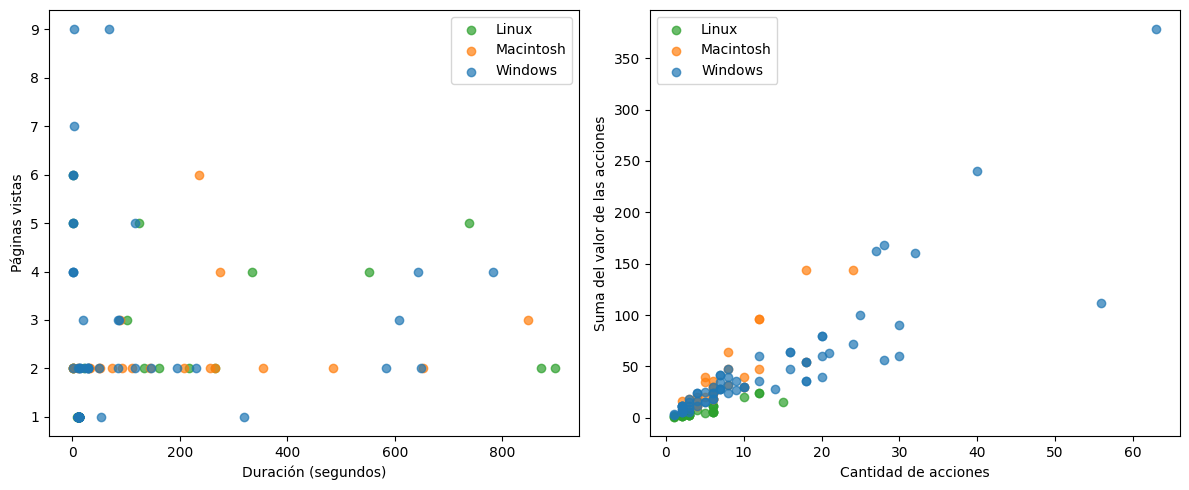

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
colores = {"Windows": "C0", "Macintosh": "C1", "Linux": "C2"}
for nombre, grupo in entrenamiento.groupby("sistema_operativo"):
    ejes[0].scatter(grupo["duracion"], grupo["paginas"], label=nombre, alpha=0.7, color=colores[nombre])
    ejes[1].scatter(grupo["acciones"], grupo["valor"], label=nombre, alpha=0.7, color=colores[nombre])
ejes[0].set_xlabel("Duración (segundos)"); ejes[0].set_ylabel("Páginas vistas"); ejes[0].legend()
ejes[1].set_xlabel("Cantidad de acciones"); ejes[1].set_ylabel("Suma del valor de las acciones"); ejes[1].legend()
plt.tight_layout(); plt.show()

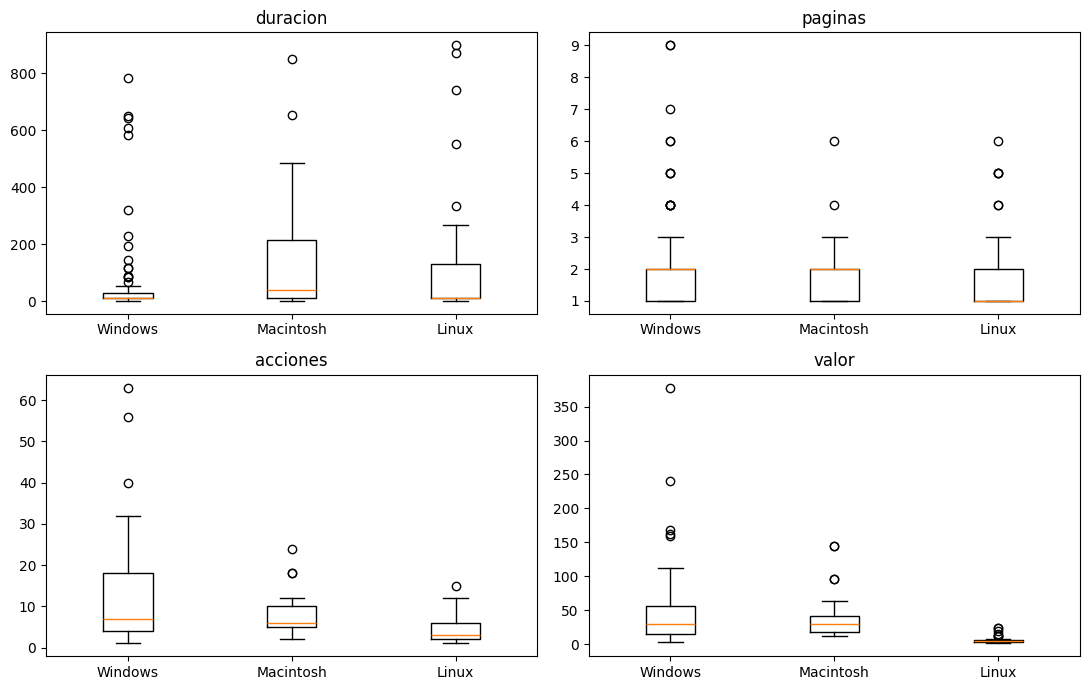

In [10]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(ejes.ravel(), ["duracion", "paginas", "acciones", "valor"]):
    datos_por_clase = [entrenamiento.loc[entrenamiento["sistema_operativo"] == c, col]
                       for c in ["Windows", "Macintosh", "Linux"]]
    ax.boxplot(datos_por_clase, tick_labels=["Windows", "Macintosh", "Linux"])
    ax.set_title(col)
plt.tight_layout(); plt.show()

In [11]:
corr = entrenamiento[["duracion", "paginas", "acciones", "valor"]].corr()
print(corr.round(2))

          duracion  paginas  acciones  valor
duracion      1.00     0.21      0.13   0.08
paginas       0.21     1.00      0.74   0.61
acciones      0.13     0.74      1.00   0.87
valor         0.08     0.61      0.87   1.00


**Qué encuentro en la exploración (verificable en las salidas de arriba):**
- Los usuarios de Linux tienen, en promedio, muchas menos acciones y un valor de acciones mucho más bajo que Windows y Macintosh.
- Windows y Macintosh se parecen bastante en `paginas` y `valor`, y se diferencian más por `duracion` (Macintosh tiende a sesiones más largas en este conjunto).
- `acciones` y `valor` están bastante correlacionadas entre sí (es esperable: más acciones probablemente sumen más valor).
- Los gráficos de dispersión muestran a los tres grupos parcialmente superpuestos, no separados con nitidez: no espero una clasificación perfecta.
- Las escalas son muy distintas entre columnas (duración llega a 898, páginas a 9): esto importa porque la regresión logística con regularización es sensible a la escala.

## 3. Modelado de datos
### 3.1 Preprocesamiento reproducible
Todas las entradas son numéricas continuas o de conteo, sin categóricas ni faltantes, así que el único paso necesario es el **escalado**. Igual lo armo con un `Pipeline` para que el ajuste (`fit`) se haga solo con el entrenamiento y se reutilice (`transform`) en la prueba, evitando fuga de información.

In [12]:
modelo_logistico = Pipeline([
    ("escalar", StandardScaler()),
    ("clasificador", linear_model.LogisticRegression(max_iter=1000)),
])
modelo_logistico.fit(X_entrenamiento, Y_entrenamiento)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('escalar', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, ma

### 3.2 Evaluación sobre el conjunto de prueba

In [13]:
prediccion = modelo_logistico.predict(X_prueba)
print("Exactitud (accuracy):", round(accuracy_score(Y_prueba, prediccion), 3))
print()
print(classification_report(Y_prueba, prediccion, target_names=["Windows", "Macintosh", "Linux"]))

Exactitud (accuracy): 0.706

              precision    recall  f1-score   support

     Windows       0.75      0.71      0.73        17
   Macintosh       1.00      0.38      0.55         8
       Linux       0.60      1.00      0.75         9

    accuracy                           0.71        34
   macro avg       0.78      0.69      0.67        34
weighted avg       0.77      0.71      0.69        34



Como las clases están algo desbalanceadas, no me quedo solo con la accuracy: reviso precisión y recall por clase (`classification_report`).

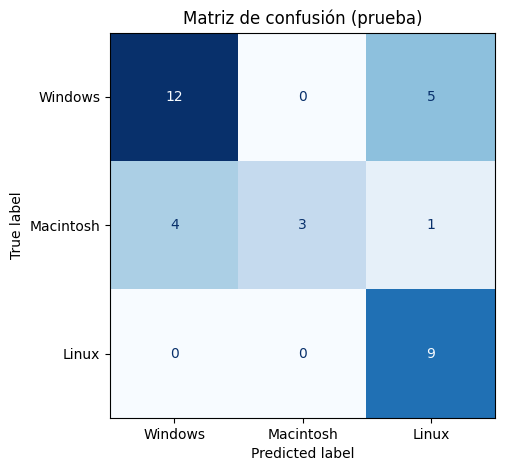

In [14]:
matriz = confusion_matrix(Y_prueba, prediccion)
disp = ConfusionMatrixDisplay(matriz, display_labels=["Windows", "Macintosh", "Linux"])
fig, ax = plt.subplots(figsize=(5.5, 5))
disp.plot(ax=ax, colorbar=False, cmap="Blues")
plt.title("Matriz de confusión (prueba)")
plt.show()

### 3.3 Robustez: validación cruzada sobre el entrenamiento
Con solo 34 datos de prueba (20 % de 170), la exactitud de un único split puede variar bastante según qué usuarios caigan ahí. Repito la evaluación con validación cruzada estratificada de 5 particiones sobre el entrenamiento; como el escalado está dentro del pipeline, se reajusta en cada partición sin fuga de información.

In [15]:
resultados_cv = cross_val_score(modelo_logistico, X_entrenamiento, Y_entrenamiento, cv=5, scoring="accuracy")
print("Exactitud por partición:", resultados_cv.round(3))
print("Exactitud media (CV):", round(resultados_cv.mean(), 3), "| desvío:", round(resultados_cv.std(), 3))

Exactitud por partición: [0.679 0.593 0.741 0.593 0.704]
Exactitud media (CV): 0.662 | desvío: 0.06


### 3.4 Interpretar los coeficientes
La regresión logística multiclase (`LogisticRegression` con más de 2 clases) ajusta, por defecto, un conjunto de coeficientes por clase. Los inspecciono para entender qué variables pesan más en cada una (siempre sobre las variables ya escaladas, así los coeficientes son comparables entre sí.

In [16]:
coeficientes = pd.DataFrame(
    modelo_logistico["clasificador"].coef_,
    columns=X.columns, index=["Windows", "Macintosh", "Linux"])
coeficientes.round(3)

,duracion,paginas,acciones,valor
Windows,-0.330,-0.406,1.133,0.937
Macintosh,0.156,-0.135,-0.784,2.028
Linux,0.174,0.541,-0.349,-2.964


### 3.5 Probar con un nuevo usuario
Simulo un usuario nuevo, para ver cómo se usaría el modelo en producción.

In [17]:
usuario_nuevo = pd.DataFrame(
    [[15, 2, 12, 40], [300, 2, 3, 5]],
    columns=["duracion", "paginas", "acciones", "valor"])
prediccion_nueva = modelo_logistico.predict(usuario_nuevo)
probabilidades = modelo_logistico.predict_proba(usuario_nuevo)
for i, fila in usuario_nuevo.iterrows():
    print(f"Usuario {i}: {dict(fila)} -> predicción: {etiquetas_clase[prediccion_nueva[i]]}")
    print("  Probabilidades:", dict(zip(["Windows", "Macintosh", "Linux"], probabilidades[i].round(3))))

Usuario 0: {'duracion': np.int64(15), 'paginas': np.int64(2), 'acciones': np.int64(12), 'valor': np.int64(40)} -> predicción: Windows
  Probabilidades: {'Windows': np.float64(0.793), 'Macintosh': np.float64(0.18), 'Linux': np.float64(0.027)}
Usuario 1: {'duracion': np.int64(300), 'paginas': np.int64(2), 'acciones': np.int64(3), 'valor': np.int64(5)} -> predicción: Linux
  Probabilidades: {'Windows': np.float64(0.146), 'Macintosh': np.float64(0.173), 'Linux': np.float64(0.681)}



  Probabilidades: {'Windows': np.float64(0.793), 'Macintosh': np.float64(0.18), 'Linux': np.float64(0.027)}
Usuario 1: {'duracion': np.int64(300), 'paginas': np.int64(2), 'acciones': np.int64(3), 'valor': np.int64(5)} -> predicción: Linux
  Probabilidades: {'Windows': np.float64(0.146), 'Macintosh': np.float64(0.173), 'Linux': np.float64(0.681)}


## 4. Conclusiones 
- **Pregunta:** sí, se puede predecir el sistema operativo con un desempeño moderado a partir del comportamiento de la sesión. La exactitud en prueba y en validación cruzada están en niveles similares (ver salidas de las secciones 3.2 y 3.3), lo que sugiere que el resultado no depende demasiado de qué usuarios cayeron en la partición de prueba.
- **Qué distingue mejor a los grupos:** según la exploración, Linux se separa razonablemente bien de los otros dos por tener muy pocas acciones y valor bajo. La mayor confusión del modelo está entre Windows y Macintosh, que se parecen más entre sí en estas cuatro variables (ver matriz de confusión).
- **Por qué escalar:** las variables tienen escalas muy distintas (duración llega a los cientos, páginas a un dígito). Sin escalar, una variable con números grandes podría dominar la regularización de la regresión logística sin que eso refleje su importancia real.
- **Desbalance:** las clases no están perfectamente equilibradas (86/40/44), por eso reporto precisión y recall por clase además de la exactitud, y usé `stratify` al separar entrenamiento y prueba.
- **Limitaciones:** el dataset es chico (170 registros), lo que hace que las métricas de un solo split de prueba sean poco estables; por eso complementé con validación cruzada. Además, la separación entre Windows y Macintosh no es nítida en los gráficos de dispersión, así que es esperable que el modelo se equivoque más ahí que con Linux. Estas conclusiones son válidas para el comportamiento de sesión capturado por Google Analytics en este sitio en particular, y no necesariamente se generalizan a otro sitio web con un público distinto.